# Developed-Markets Equity Scorecard — FINAL (v16)
**CRISIL assignment.** Rank the **US, Eurozone, UK, Switzerland and Japan** by expected relative performance over the next **3–6 months**, using only the supplied dataset.

| Section | Brief step |
|---|---|
| 1 | Data, as-of date and the reconstructed price limitation |
| 2 | Step 1 — Signal construction (one indicator per pillar, frozen) |
| 3 | Step 2 — Predictive power assessment |
| 4 | Step 3 — Scorecard: pillar scores, aggregate scores, 3M and 6M rankings |
| 5 | Step 4 — Backtest |
| 6 | Step 5 — Investment view |
| 7 | Exports and the figures used in the deck |

**Signal definitions are frozen** in `Markets_Scorecard_v16_investigation.ipynb` and implemented here unchanged.
**Two views are reported side by side:** the four-pillar equal-weight **diagnostic scorecard** (the brief's requirement, and the primary product) and a **predictive score** containing only the pillars with out-of-sample evidence.
**Run order:** put the six workbooks in `data/raw/` and run all cells. The as-of date is detected from the data.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata
from IPython.display import display
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 230; pd.options.display.max_columns = 30
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v16'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']; PILLARS = ['Macro', 'Micro', 'Valuation', 'Technical']
SEED = 7; NBOOT = 2000
PCOL = {'Macro': '#1f4e79', 'Micro': '#2e8b57', 'Valuation': '#e69f00', 'Technical': '#7f6aa8'}
FIG = {}
SPEC = {'US': dict(file='US_raw_data.xlsx', eps='Monthly_EPS', fci=('GSFCI Index', -1), y2='USGGT02Y Index', fx=None),
        'Eurozone': dict(file='EUR_raw_data.xlsx', eps='BEst EPS', fci=('BFCIEU Index', +1), y2='GDBR2 Index', fx=('EURUSD BGN Curncy', 'direct')),
        'UK': dict(file='UK_raw_data.xlsx', eps='BEst EPS', fci=('GSGBFCI Index', -1), y2='GUKG2 Index', fx=('GBPUSD BGN Curncy', 'direct')),
        'Switzerland': dict(file='CH_raw_data.xlsx', eps='BEst EPS', fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', fx=('USDCHF Curncy', 'invert')),
        'Japan': dict(file='JPY_raw_data.xlsx', eps='BEst EPS', fci=('GSJPFCI Index', -1), y2='GJGB2 Index', fx=('USDJPY BGN Curncy', 'invert'))}
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M'); d['_d'] = pd.to_datetime(d['Date'])
    return d.sort_values('_d').drop_duplicates('month', keep='last').set_index('month')
RAW = {c: monthly(pd.read_excel(ROOT/'data'/'raw'/SPEC[c]['file'])) for c in COUNTRIES}
def grab(c, k):
    s = SPEC[c]; d = RAW[c]
    if k == 'fci': return s['fci'][1] * d[s['fci'][0]]
    if k == 'fx': return pd.Series(1.0, index=d.index) if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return d[{'pe': 'BEst P/E Ratio', 'eps': s['eps'], 'y2': s['y2']}[k]]
IDX = pd.period_range(max(grab(c, 'pe').first_valid_index() for c in COUNTRIES), min(RAW[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, FCI, Y2, FX = [pd.DataFrame({c: grab(c, k) for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'fci', 'y2', 'fx')]
PX = PE * EPS; PX_USD = PX * FX; R = PX_USD.pct_change(); AS_OF = IDX[-1]
COV = pd.DataFrame({'workbook': {c: SPEC[c]['file'] for c in COUNTRIES}, 'EPS field': {c: SPEC[c]['eps'] for c in COUNTRIES},
                    'FCI series': {c: SPEC[c]['fci'][0] for c in COUNTRIES}, '2Y series': {c: SPEC[c]['y2'] for c in COUNTRIES},
                    'last date in workbook': {c: str(pd.to_datetime(RAW[c]['Date']).max().date()) for c in COUNTRIES}})
display(COV)
print(f'Common monthly panel: {IDX[0]} -> {AS_OF} ({len(IDX)} months). Missing values in core fields: {int(pd.concat([PE, EPS, FCI, Y2, FX], axis=1).isna().sum().sum())}')
print(f'AS-OF DATE = {AS_OF}: the last month in which ALL FIVE markets report (the US workbook ends 30-Apr-2026).')
print('DISCLOSURE: every "current" reading below is AS OF 30-APR-2026. It is not November-2026 data and is not presented as such.')
FIG['as_of'] = str(AS_OF); FIG['panel_start'] = str(IDX[0]); FIG['panel_months'] = len(IDX)

,workbook,EPS field,FCI series,2Y series,last date in workbook
US,US_raw_data.xlsx,Monthly_EPS,GSFCI Index,USGGT02Y Index,2026-04-30
Eurozone,EUR_raw_data.xlsx,BEst EPS,BFCIEU Index,GDBR2 Index,2026-06-29
UK,UK_raw_data.xlsx,BEst EPS,GSGBFCI Index,GUKG2 Index,2026-07-02
Switzerland,CH_raw_data.xlsx,BEst EPS,GSEAFCI Index,GSWISS02 Index,2026-07-14
Japan,JPY_raw_data.xlsx,BEst EPS,GSJPFCI Index,GJGB2 Index,2026-06-29


Common monthly panel: 2005-12 -> 2026-04 (245 months). Missing values in core fields: 0
AS-OF DATE = 2026-04: the last month in which ALL FIVE markets report (the US workbook ends 30-Apr-2026).
DISCLOSURE: every "current" reading below is AS OF 30-APR-2026. It is not November-2026 data and is not presented as such.


### 1a. The dataset contains no index price — what that means for the Technical pillar
The supplied "Price" workbook holds **P/E ratios**, not index levels (values 8–39; a real S&P 500 level is ~700–6,000). The index level is therefore reconstructed as
$$P=(P/E)\times EPS \qquad\text{(an identity, since } P/E \equiv P/EPS)$$
The US reconstruction matches published S&P 500 monthly returns to 0.04 pp. The other four cannot be validated against a published index with this data.
**Consequence, stated plainly:** $\log(P_t/P_{t-k}) = \log(PE_t/PE_{t-k}) + \log(EPS_t/EPS_{t-k})$, so any technical signal here is a function of the same inputs as the Valuation and Micro pillars. It is **not** an independent fourth source of information.

In [2]:
RLOC = PX.pct_change()
known = {'2008-09': -9.08, '2008-10': -16.94, '2009-02': -10.99, '2011-09': -7.18, '2018-12': -9.18, '2020-03': -12.51, '2020-04': 12.68, '2022-04': -8.80}
SPX = pd.DataFrame([{'month': k, 'reconstructed US %': RLOC['US'].loc[pd.Period(k, 'M')] * 100, 'published S&P 500 %': v} for k, v in known.items()]).set_index('month')
SPX['difference (pp)'] = SPX['reconstructed US %'] - SPX['published S&P 500 %']; display(SPX.round(2))
FIG['spx_mad_pp'] = float(SPX['difference (pp)'].abs().mean())
print(f'Mean absolute difference: {FIG["spx_mad_pp"]:.3f} pp. Reconstructed annualised volatility: ' + ', '.join(f'{c} {RLOC[c].std()*np.sqrt(12):.1%}' for c in COUNTRIES))
print('Returns are PRICE returns: no dividend data is supplied, so total returns cannot be computed.')

,reconstructed US %,published S&P 500 %,difference (pp)
month,,,
2008-09,-9.090,-9.080,-0.010
2008-10,-16.970,-16.940,-0.030
2009-02,-11.000,-10.990,-0.010
2011-09,-7.170,-7.180,0.010
2018-12,-9.350,-9.180,-0.170
2020-03,-12.530,-12.510,-0.020
2020-04,12.700,12.680,0.020
2022-04,-8.830,-8.800,-0.030


Mean absolute difference: 0.039 pp. Reconstructed annualised volatility: US 15.2%, Eurozone 16.5%, UK 13.1%, Switzerland 12.5%, Japan 17.2%
Returns are PRICE returns: no dividend data is supplied, so total returns cannot be computed.


## 2. Step 1 — Signal construction (frozen)

In [3]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
pit_z = lambda d, mp=36: (d - d.expanding(mp).mean()) / d.expanding(mp).std()
own_sd = lambda d, mp=36: d / d.expanding(mp).std()
def trend_q(P, w=12):
    lp = np.log(P); t = pd.Series(np.arange(len(lp)), index=lp.index, dtype=float)
    cr = lp.apply(lambda s: s.rolling(w).corr(t)); return (cr ** 2) * np.sign(cr)
EY = 100.0 / PE
RAWSIG = {'Macro': own_sd(FCI - FCI.shift(6)), 'Micro': EPS / EPS.shift(6) - 1,
          'Valuation': pit_z(EY - Y2, 36), 'Technical': trend_q(PX, 12)}
Z = {p: cs_z(v) for p, v in RAWSIG.items()}
SIGDOC = pd.DataFrame([
 {'pillar': 'Macro', 'indicator': 'FCI 6M easing', 'economic rationale': 'Easier financing conditions — lower rates and spreads, calmer markets, a weaker currency — support valuations and risk appetite with a lag.',
  'construction': '(FCI_t − FCI_t−6) ÷ expanding sd of that 6M change (≥36 obs); FCI oriented so higher = easier', 'direction': 'more easing ⇒ more attractive',
  'lookback': '6M change; expanding sd', 'standardisation': 'own-history scaling, then cross-sectional z', 'data source': 'GSFCI (US), BFCIEU (EZ), GSGBFCI (UK), GSEAFCI (CH — euro-area), GSJPFCI (JP)'},
 {'pillar': 'Micro', 'indicator': 'EPS revision 6M', 'economic rationale': 'Analysts revise forecasts gradually, so upgrades persist and prices under-react to them.',
  'construction': 'EPS_t / EPS_t−6 − 1 on 12M-forward consensus EPS', 'direction': 'stronger upgrades ⇒ more attractive',
  'lookback': '6 months', 'standardisation': 'cross-sectional z', 'data source': 'Monthly_EPS (US), BEst EPS (EZ, UK, CH, JP)'},
 {'pillar': 'Valuation', 'indicator': 'Earnings-yield spread vs own history', 'economic rationale': 'The forward earnings yield relative to the local risk-free alternative measures how much an investor is paid to hold equities; judged against each market\'s own history rather than against structurally different peers.',
  'construction': '(100 / forward P/E − 2Y government yield), expanding within-country z (≥36 obs)', 'direction': 'wider spread vs own history ⇒ more attractive',
  'lookback': 'expanding window', 'standardisation': 'own-history z, then cross-sectional z', 'data source': 'BEst P/E Ratio and the 2Y government yield for each market'},
 {'pillar': 'Technical', 'indicator': 'Signed trend quality 12M', 'economic rationale': 'A smooth, directional price path suggests information is being absorbed gradually rather than in shocks; the sign ensures a smooth DECLINE scores negatively.',
  'construction': 'sign(slope) × R² from a regression of log reconstructed price on a 12-month time trend', 'direction': 'smooth rising trend ⇒ more attractive',
  'lookback': '12 months', 'standardisation': 'cross-sectional z', 'data source': 'Reconstructed index = BEst P/E × forward EPS (see §1a)'}]).set_index('pillar')
display(SIGDOC); SIGDOC.to_csv(OUT/'signal_definitions.csv')
print('First month each indicator is available for all five markets:', {p: str(Z[p].dropna().index.min()) for p in PILLARS})

,indicator,economic rationale,construction,direction,lookback,standardisation,data source
pillar,,,,,,,
Macro,FCI 6M easing,Easier financing conditions — lower rates and ...,(FCI_t − FCI_t−6) ÷ expanding sd of that 6M ch...,more easing ⇒ more attractive,6M change; expanding sd,"own-history scaling, then cross-sectional z","GSFCI (US), BFCIEU (EZ), GSGBFCI (UK), GSEAFCI..."
Micro,EPS revision 6M,"Analysts revise forecasts gradually, so upgrad...",EPS_t / EPS_t−6 − 1 on 12M-forward consensus EPS,stronger upgrades ⇒ more attractive,6 months,cross-sectional z,"Monthly_EPS (US), BEst EPS (EZ, UK, CH, JP)"
Valuation,Earnings-yield spread vs own history,The forward earnings yield relative to the loc...,"(100 / forward P/E − 2Y government yield), exp...",wider spread vs own history ⇒ more attractive,expanding window,"own-history z, then cross-sectional z",BEst P/E Ratio and the 2Y government yield for...
Technical,Signed trend quality 12M,"A smooth, directional price path suggests info...",sign(slope) × R² from a regression of log reco...,smooth rising trend ⇒ more attractive,12 months,cross-sectional z,Reconstructed index = BEst P/E × forward EPS (...


First month each indicator is available for all five markets: {'Macro': '2009-05', 'Micro': '2006-06', 'Valuation': '2008-11', 'Technical': '2006-11'}


## 3. Step 2 — Predictive power assessment
**Metric:** monthly Spearman rank IC between the five pillar scores and the next 3M or 6M USD return **relative to the five-market average**.
**Windows:** DISCOVERY = signal months to 2016-12 · six-month embargo · **EXAMINED** = 2017-07 onward.
The examined window was inspected repeatedly across v1–v15, so it is **not** untouched holdout data.
**Inference:** 95% moving-block bootstrap CI (block = 2 × horizon), HAC t (lags = horizon), and a block-permutation p (country labels shuffled in horizon-length blocks, 5,000 draws).

In [4]:
def rel(df, h):
    r = df.shift(-h) / df - 1; return r.sub(r.mean(axis=1), axis=0)
TGT = {('ret', h): rel(PX_USD, h) for h in (3, 6)} | {('mult', h): rel(PE, h) for h in (3, 6)}
EMB_END, EXAM_START = pd.Period('2016-12', 'M'), pd.Period('2017-07', 'M')
def unit_ranks(A):
    r = rankdata(A, axis=-1) - (A.shape[-1] + 1) / 2.0; return r / np.sqrt((r ** 2).sum(-1, keepdims=True))
def ic_parts(S, Y):
    s = S.to_numpy(float); y = Y.reindex(S.index).to_numpy(float); ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    return pd.DataFrame(unit_ranks(s[ok]) * unit_ranks(y[ok]), index=S.index[ok], columns=S.columns)
def ic_series(S, Y): return ic_parts(S, Y).sum(axis=1)
def hac_t(x, lags):
    x = np.asarray(x, float); return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0])
def mbb(x, L, n=NBOOT, seed=SEED):
    x = np.asarray(x, float); T = len(x); rng = np.random.default_rng(seed); nb = int(np.ceil(T / L))
    st = rng.integers(0, T - L + 1, (n, nb)); m = x[(st[:, :, None] + np.arange(L)).reshape(n, -1)[:, :T]].mean(1)
    return tuple(np.percentile(m, [2.5, 97.5]))
def perm_p(S, Y, months, h, n=5000, seed=SEED):
    RS = unit_ranks(S.reindex(months).to_numpy(float)); RY = unit_ranks(Y.reindex(months).to_numpy(float)); T = len(months); blk = np.arange(T) // h
    P = np.random.default_rng(seed).permuted(np.tile(np.arange(5), (n, blk.max() + 1, 1)), axis=2)[:, blk, :]
    null = (RS[None] * np.take_along_axis(np.broadcast_to(RY, (n, T, 5)), P, axis=2)).sum(-1).mean(-1)
    return (1 + (null >= (RS * RY).sum(-1).mean()).sum()) / (1 + n)
rows, crows = [], []
for p in PILLARS:
    for h in (3, 6):
        ic = ic_series(Z[p], TGT[('ret', h)])
        for wl, x in (('discovery', ic[ic.index <= EMB_END]), ('examined', ic[ic.index >= EXAM_START]), ('full', ic)):
            lo, hi = mbb(x.values, 2 * h)
            rows.append({'pillar': p, 'horizon': f'{h}M', 'window': wl, 'months': len(x), 'from': str(x.index.min()), 'to': str(x.index.max()),
                         'IC': x.mean(), 'CI 2.5%': lo, 'CI 97.5%': hi, 'HAC t': hac_t(x.values, h), 'perm p': perm_p(Z[p], TGT[('ret', h)], x.index, h), 'hit rate': (x > 0).mean()})
            if wl != 'full':
                c = ic_parts(Z[p], TGT[('ret', h)]).reindex(x.index).mean()
                crows.append({'pillar': p, 'horizon': f'{h}M', 'window': wl, **c.to_dict(), 'total = IC': c.sum()})
PP = pd.DataFrame(rows).set_index(['pillar', 'horizon', 'window'])
display(PP.drop(columns=['from', 'to']).style.format({c: '{:+.3f}' for c in ('IC', 'CI 2.5%', 'CI 97.5%')} | {'HAC t': '{:+.2f}', 'perm p': '{:.3f}', 'hit rate': '{:.0%}', 'months': '{:.0f}'}))
PP.to_csv(OUT/'predictive_power.csv')
CT = pd.DataFrame(crows).set_index(['pillar', 'horizon', 'window'])
print('Country contributions to the mean IC (the five columns sum exactly to the IC):')
display(CT.style.format('{:+.3f}').background_gradient(axis=None, cmap='RdBu', vmin=-.08, vmax=.08, subset=COUNTRIES))
CT.to_csv(OUT/'country_contributions.csv')

Country contributions to the mean IC (the five columns sum exactly to the IC):


### 3a. Robustness: leave-one-country-out, walk-forward, and overlap with other pillars

In [5]:
def loo(p, drop, h):
    keep = [c for c in COUNTRIES if c != drop]
    raw = {'Macro': own_sd(FCI[keep] - FCI[keep].shift(6)), 'Micro': EPS[keep] / EPS[keep].shift(6) - 1,
           'Valuation': pit_z(EY[keep] - Y2[keep], 36), 'Technical': trend_q(PX[keep], 12)}[p]
    y = PX_USD[keep].shift(-h) / PX_USD[keep] - 1; y = y.sub(y.mean(axis=1), axis=0)
    return ic_series(cs_z(raw), y)
IC6 = {p: ic_series(Z[p], TGT[('ret', 6)]) for p in PILLARS}; IC3 = {p: ic_series(Z[p], TGT[('ret', 3)]) for p in PILLARS}
def walkfwd(p, h):
    ics = (IC3 if h == 3 else IC6)[p]; out = []
    for Y in range(2014, AS_OF.year + 1):
        f = ics[(ics.index >= pd.Period(f'{Y}-01', 'M')) & (ics.index <= pd.Period(f'{Y}-12', 'M'))]
        if ics[ics.index <= pd.Period(f'{Y-1}-06', 'M')].shape[0] >= 48: out += list(f.values)
    return np.array(out)
def orth(S, ctrls):
    out = pd.DataFrame(index=S.index, columns=S.columns, dtype=float)
    for t in S.index:
        y = S.loc[t].to_numpy(float); X = np.column_stack([c.loc[t].to_numpy(float) for c in ctrls])
        if np.isnan(y).any() or np.isnan(X).any(): continue
        X = np.column_stack([np.ones(len(y)), X]); out.loc[t] = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    return cs_z(out)
rows = []
for p in PILLARS:
    others = [Z[q] for q in PILLARS if q != p]
    for h in (3, 6):
        base = PP.loc[(p, f'{h}M', 'full'), 'IC']; w = walkfwd(p, h)
        loos = {c: loo(p, c, h).mean() for c in COUNTRIES}
        res = ic_series(orth(Z[p], others), TGT[('ret', h)])
        rows.append({'pillar': p, 'horizon': f'{h}M', 'IC full': base, 'min leave-one-out IC': min(loos.values()), 'ex-US IC': loos['US'],
                     'IC 2014-onward (frozen)': w.mean(), 'IC 2014-onward t': hac_t(w, h),
                     'IC after removing the other 3 pillars': res.mean(), 'share of IC retained': res.mean() / base if abs(base) > 1e-9 else np.nan})
ROB = pd.DataFrame(rows).set_index(['pillar', 'horizon'])
display(ROB.style.format({c: '{:+.3f}' for c in ROB.columns if 'IC' in c} | {'IC 2014-onward t': '{:+.2f}', 'share of IC retained': '{:.0%}'}))
ROB.to_csv(OUT/'robustness.csv')

### 3b. Confidence labels
Rules fixed before reading the table. **Multiple-testing caveat applies to all four:** these indicators were selected across v1–v16 research; selection-adjusted p-values for the strongest are 0.16–0.20, a nominal 5% HAC test over-rejects at 6–9% in samples this short, and the examined window is not untouched. **No pillar is statistically significant.**

,indicator,IC 3M examined,IC 6M examined,IC 6M from 2014,ex-US IC 6M,confidence label,basis
Macro,FCI 6M easing,0.127,0.173,0.162,0.151,PREDICTIVE (provisional),Positive in both windows at both horizons; eve...
Micro,EPS revision 6M,0.131,0.074,0.165,0.105,"PREDICTIVE (provisional, 3M)",Positive in both windows at 3M; weaker at 6M i...
Valuation,Earnings-yield spread vs own history,-0.093,-0.053,0.060,0.191,DIAGNOSTIC,Strong in discovery (+0.30 at 6M) but negative...
Technical,Signed trend quality 12M,0.158,0.163,0.175,0.007,DIAGNOSTIC,Raw IC looks strong (+0.133 at 6M) but only ~4...


PREDICTIVE pillars: ['Macro', 'Micro']   |   DIAGNOSTIC-only pillars: ['Valuation', 'Technical']

"IC 2014-onward" is simply the frozen signal measured from 2014; it involves no selection. The true walk-forward test — re-choosing each pillar's construction every year from past data only — is in the investigation notebook: Macro +0.162 (t 2.26), Micro +0.113, Valuation +0.060, Technical +0.113 within a restricted menu and +0.058 across the wider v15 menu.


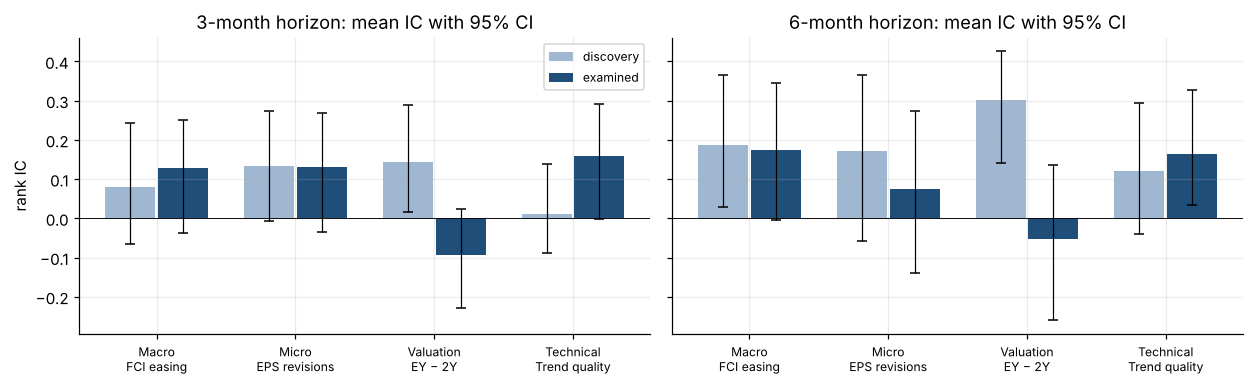

In [6]:
LABELS = {
 'Macro': ('PREDICTIVE (provisional)', 'Positive in both windows at both horizons; every leave-one-out IC positive; retains most of its IC against the other pillars. In the investigation notebook its walk-forward IC (construction re-chosen yearly) is +0.162, t 2.26 — the only pillar to hold up under that test.'),
 'Micro': ('PREDICTIVE (provisional, 3M)', 'Positive in both windows at 3M; weaker at 6M in the examined window. Revision acceleration and revision momentum were tested and refuted.'),
 'Valuation': ('DIAGNOSTIC', 'Strong in discovery (+0.30 at 6M) but negative in the examined window. Traced to the US: it was persistently the most expensive market and persistently outperformed. Excluding the US the examined IC is positive (+0.08).'),
 'Technical': ('DIAGNOSTIC', 'Raw IC looks strong (+0.133 at 6M) but only ~43% survives removing Micro and Valuation, and it collapses to +0.007 without the US. No momentum variant survives ex-US; reversal is absent. The dataset has no index price, so an independent technical pillar is not available.')}
NOTE_WF = ('"IC 2014-onward" is simply the frozen signal measured from 2014; it involves no selection. '
           'The true walk-forward test — re-choosing each pillar\'s construction every year from past data only — is in the investigation notebook: '
           'Macro +0.162 (t 2.26), Micro +0.113, Valuation +0.060, Technical +0.113 within a restricted menu and +0.058 across the wider v15 menu.')
CLS = pd.DataFrame({p: {'indicator': SIGDOC.loc[p, 'indicator'], 'IC 3M examined': PP.loc[(p, '3M', 'examined'), 'IC'], 'IC 6M examined': PP.loc[(p, '6M', 'examined'), 'IC'],
                        'IC 6M from 2014': ROB.loc[(p, '6M'), 'IC 2014-onward (frozen)'], 'ex-US IC 6M': ROB.loc[(p, '6M'), 'ex-US IC'],
                        'confidence label': LABELS[p][0], 'basis': LABELS[p][1]} for p in PILLARS}).T
display(CLS); CLS.to_csv(OUT/'signal_classification.csv')
PRED_PILLARS = [p for p in PILLARS if LABELS[p][0].startswith('PREDICTIVE')]
print(f'PREDICTIVE pillars: {PRED_PILLARS}   |   DIAGNOSTIC-only pillars: {[p for p in PILLARS if p not in PRED_PILLARS]}')
print('\n' + NOTE_WF)
FIG['labels'] = {p: LABELS[p][0] for p in PILLARS}
FIG['ic'] = {p: {f'{w} {h}M': float(PP.loc[(p, f'{h}M', w), 'IC']) for w in ('discovery', 'examined') for h in (3, 6)} for p in PILLARS}
FIG['ci_exam'] = {p: {f'{h}M': [float(PP.loc[(p, f'{h}M', 'examined'), 'CI 2.5%']), float(PP.loc[(p, f'{h}M', 'examined'), 'CI 97.5%'])] for h in (3, 6)} for p in PILLARS}
FIG['ic2014'] = {p: {f'{h}M': float(ROB.loc[(p, f'{h}M'), 'IC 2014-onward (frozen)']) for h in (3, 6)} for p in PILLARS}
FIG['exus'] = {p: float(ROB.loc[(p, '6M'), 'ex-US IC']) for p in PILLARS}
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
for ax, h in zip(axs, (3, 6)):
    x = np.arange(4)
    for k, (w, off, col) in enumerate((('discovery', -.19, '#9fb7d0'), ('examined', .19, '#1f4e79'))):
        v = [PP.loc[(p, f'{h}M', w), 'IC'] for p in PILLARS]; lo = [PP.loc[(p, f'{h}M', w), 'CI 2.5%'] for p in PILLARS]; hi = [PP.loc[(p, f'{h}M', w), 'CI 97.5%'] for p in PILLARS]
        ax.bar(x + off, v, .36, color=col, label=w, yerr=[np.array(v) - lo, np.array(hi) - v], capsize=3, error_kw={'lw': .8})
    ax.axhline(0, c='k', lw=.6); ax.set_xticks(x); ax.set_xticklabels(['Macro\nFCI easing', 'Micro\nEPS revisions', 'Valuation\nEY − 2Y', 'Technical\nTrend quality'], fontsize=8)
    ax.set_title(f'{h}-month horizon: mean IC with 95% CI')
axs[0].set_ylabel('rank IC'); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'ic_by_pillar.png', dpi=220, bbox_inches='tight'); plt.show()

## 4. Step 3 — Scorecard construction
* **Pillar score** = the indicator's cross-sectional z-score across the five markets each month.
* **Diagnostic scorecard (primary, as the brief specifies)** = equal-weight average of the four pillar scores. A pillar's contribution = ¼ × its z.
* **Predictive score (companion)** = equal-weight average of the pillars labelled PREDICTIVE (Macro and Micro). The two DIAGNOSTIC pillars are shown with their scores but carry **zero** predictive weight — they are not deleted and not given artificial importance.
* **Rankings** are produced for both the 3M and 6M horizons. The pillar scores do not change with horizon; the horizon labels record which evidence supports each ranking.
* **Weights are equal and fixed.** No weight is fitted to historical performance, which would be in-sample optimisation.

In [7]:
valid = pd.concat([Z[p].notna().all(axis=1) for p in PILLARS], axis=1).all(axis=1)
DIAG = (sum(Z[p] for p in PILLARS) / 4).where(valid, axis=0)
PRED = (sum(Z[p] for p in PRED_PILLARS) / len(PRED_PILLARS)).where(valid, axis=0)
RANK_D = DIAG.rank(axis=1, ascending=False); RANK_P = PRED.rank(axis=1, ascending=False)
print(f'Scorecard defined from {DIAG.dropna().index.min()} to {AS_OF} ({int(valid.sum())} months). The start is set by the Macro indicator (expanding sd, ≥36 obs).')
rows = []
for t in DIAG.dropna().index:
    for c in COUNTRIES:
        rows.append({'month': str(t), 'country': c, **{f'{p} score': Z[p].loc[t, c] for p in PILLARS},
                     **{f'{p} contribution': Z[p].loc[t, c] / 4 for p in PILLARS},
                     'diagnostic score': DIAG.loc[t, c], 'diagnostic rank': int(RANK_D.loc[t, c]),
                     'predictive score': PRED.loc[t, c], 'predictive rank': int(RANK_P.loc[t, c]),
                     'call (predictive)': 'OVERWEIGHT' if RANK_P.loc[t, c] <= 2 else ('UNDERWEIGHT' if RANK_P.loc[t, c] >= 4 else 'NEUTRAL'),
                     'realised next 3M relative return': TGT[('ret', 3)].loc[t, c], 'realised next 6M relative return': TGT[('ret', 6)].loc[t, c]})
HIST = pd.DataFrame(rows); HIST.to_csv(OUT/'scorecard_history.csv', index=False)
rows = []
for nm, S in (('Diagnostic (4 pillars, equal weight)', DIAG), ('Predictive (Macro + Micro)', PRED)):
    for h in (3, 6):
        ic = ic_series(S, TGT[('ret', h)])
        for wl, x in (('discovery', ic[ic.index <= EMB_END]), ('examined', ic[ic.index >= EXAM_START]), ('full', ic)):
            lo, hi = mbb(x.values, 2 * h)
            rows.append({'score': nm, 'horizon': f'{h}M', 'window': wl, 'months': len(x), 'IC': x.mean(), 'CI 2.5%': lo, 'CI 97.5%': hi, 'HAC t': hac_t(x.values, h)})
SCIC = pd.DataFrame(rows).set_index(['score', 'horizon', 'window'])
display(SCIC.style.format({c: '{:+.3f}' for c in ('IC', 'CI 2.5%', 'CI 97.5%')} | {'HAC t': '{:+.2f}', 'months': '{:.0f}'}))
SCIC.to_csv(OUT/'scorecard_ic.csv')
FIG['score_ic'] = {nm: {f'{w} {h}M': float(SCIC.loc[(nm, f'{h}M', w), 'IC']) for w in ('discovery', 'examined') for h in (3, 6)} for nm in SCIC.index.get_level_values(0).unique()}
print('The diagnostic score carries the two DIAGNOSTIC pillars, so its examined-window IC is weaker than the predictive score. Both are reported.')

Scorecard defined from 2009-05 to 2026-04 (204 months). The start is set by the Macro indicator (expanding sd, ≥36 obs).


The diagnostic score carries the two DIAGNOSTIC pillars, so its examined-window IC is weaker than the predictive score. Both are reported.


## 5. Step 4 — Backtest
**Rules, fixed in advance and not optimised:**
* Signal at month-end t; positions earn the month t+1 USD price return (no dividends).
* **Long-only:** 50% in each of the top-2 ranked markets. **Benchmark:** equal weight (20% each), carried cost-free.
* **Long-short, two versions:** top-2 vs bottom-2 (±50% each) and top-1 vs bottom-1 (±100%). Self-financing, so Sharpe uses rf = 0.
* **6-month overlapping tranches** (matching the 3–6M objective); positions drift with prices inside a tranche and turnover includes the drift re-trading.
* **Costs:** one-way 0 / 5 / 10 / 20 bps on traded weight, both legs.

In [8]:
RV = R.to_numpy(float); T_ = len(IDX)
def weights(z, kind):
    rk = rankdata(-z)
    if kind == 'LO2': return np.where(rk <= 2, .5, 0.)
    if kind == 'LS2': return np.where(rk <= 2, .5, np.where(rk >= 4, -.5, 0.))
    if kind == 'LS1': return np.where(rk == 1, 1., np.where(rk == 5, -1., 0.))
def simulate(score, kind, H=6):
    SV = score.to_numpy(float); i0 = next(i for i in range(T_) if not np.isnan(SV[i]).any())
    tr, g, tn, hd = [], np.full(T_, np.nan), np.full(T_, np.nan), np.full((T_, 5), np.nan)
    for i in range(i0, T_):
        pre = sum((w for _, w in tr), np.zeros(5)); tr = [[a + 1, w] for a, w in tr if a + 1 < H]
        wn = weights(SV[i], kind) / H
        tr = [[k, wn.copy()] for k in range(H)] if i == i0 else tr + [[0, wn]]
        agg = sum((w for _, w in tr), np.zeros(5)); hd[i] = agg; tn[i] = np.abs(agg - pre).sum()
        if i + 1 < T_:
            r = RV[i + 1]; rp = float(agg @ r); g[i + 1] = rp; tr = [[a, w * (1 + r) / (1 + rp)] for a, w in tr]
    return pd.Series(g, IDX), pd.Series(tn, IDX).shift(1), pd.DataFrame(hd, IDX, COUNTRIES)
EW = R.mean(axis=1); START = DIAG.dropna().index.min() + 1
WIN = {'full': (START, AS_OF), 'discovery': (START, EMB_END), 'examined': (pd.Period('2017-08', 'M'), AS_OF)}
def metrics(net, bench=None, turn=None, bps=0):
    cum = (1 + net).cumprod(); d = {'Return % p.a.': (cum.iloc[-1] ** (12 / len(net)) - 1) * 100, 'Vol % p.a.': net.std() * np.sqrt(12) * 100,
                                    'Sharpe': net.mean() / net.std() * np.sqrt(12), 'Max drawdown %': (cum / cum.cummax() - 1).min() * 100}
    if turn is not None: d |= {'Turnover p.a. (x)': turn.mean() * 12, 'Cost drag % p.a.': turn.mean() * 12 * bps / 100}
    if bench is not None:
        a = net - bench; ca = (1 + a).cumprod()
        d |= {'Excess vs EW % p.a.': a.mean() * 1200, 'Tracking error %': a.std() * np.sqrt(12) * 100, 'Information ratio': a.mean() / a.std() * np.sqrt(12),
              'Max relative drawdown %': (ca / ca.cummax() - 1).min() * 100}
    return d
BT = {(nm, k): simulate(S, k) for nm, S in (('Diagnostic (4-pillar)', DIAG), ('Predictive (Macro+Micro)', PRED)) for k in ('LO2', 'LS2', 'LS1')}
BOOK = {'LO2': 'long-only top-2', 'LS2': 'long-short top2/bottom2', 'LS1': 'long-short top1/bottom1'}
rows = []
for wl, (a, b) in WIN.items():
    sl = lambda s: s.loc[a:b]
    rows.append({'window': wl, 'strategy': 'Equal-weight benchmark', 'book': 'long-only', 'cost bps': 0, **metrics(sl(EW))})
    for (nm, k), (g, tn, hd) in BT.items():
        for bps in (0, 5, 10, 20):
            rows.append({'window': wl, 'strategy': nm, 'book': BOOK[k], 'cost bps': bps,
                         **metrics(sl(g - tn * bps * 1e-4), sl(EW) if k == 'LO2' else None, sl(tn), bps)})
BTS = pd.DataFrame(rows).set_index(['window', 'strategy', 'book', 'cost bps'])
display(BTS.round(2)); BTS.to_csv(OUT/'backtest_summary.csv')
MON = pd.DataFrame({'EW benchmark': EW} | {f'{nm} | {BOOK[k]} | gross': BT[(nm, k)][0] for nm, k in BT}
                   | {f'{nm} | {BOOK[k]} | net 10bps': BT[(nm, k)][0] - BT[(nm, k)][1] * 1e-3 for nm, k in BT}
                   | {f'{nm} | {BOOK[k]} | turnover': BT[(nm, k)][1] for nm, k in BT}).loc[START:]
MON.index = MON.index.astype(str); MON.to_csv(OUT/'backtest_monthly.csv')
def bget(w, s, bk, c, col): return float(BTS.loc[(w, s, bk, c), col])
FIG['bt'] = {w: {f'{s}|{bk}|{col}': bget(w, s, bk, 10 if s != 'Equal-weight benchmark' else 0, col)
                 for s, bk in [('Diagnostic (4-pillar)', 'long-only top-2'), ('Diagnostic (4-pillar)', 'long-short top2/bottom2'), ('Diagnostic (4-pillar)', 'long-short top1/bottom1'),
                               ('Predictive (Macro+Micro)', 'long-only top-2'), ('Predictive (Macro+Micro)', 'long-short top2/bottom2'), ('Equal-weight benchmark', 'long-only')]
                 for col in ('Return % p.a.', 'Vol % p.a.', 'Sharpe', 'Max drawdown %')
                 if (s, bk, col) != ('Equal-weight benchmark', 'long-only', 'Turnover p.a. (x)')} for w in WIN}
FIG['bt_extra'] = {w: {'LO_ir': bget(w, 'Diagnostic (4-pillar)', 'long-only top-2', 10, 'Information ratio'),
                       'LO_excess': bget(w, 'Diagnostic (4-pillar)', 'long-only top-2', 10, 'Excess vs EW % p.a.'),
                       'LO_turn': bget(w, 'Diagnostic (4-pillar)', 'long-only top-2', 10, 'Turnover p.a. (x)'),
                       'LS2_turn': bget(w, 'Diagnostic (4-pillar)', 'long-short top2/bottom2', 10, 'Turnover p.a. (x)'),
                       'PRED_LO_ir': bget(w, 'Predictive (Macro+Micro)', 'long-only top-2', 10, 'Information ratio')} for w in WIN}
FIG['bt_cost'] = {str(b): bget('full', 'Diagnostic (4-pillar)', 'long-short top2/bottom2', b, 'Sharpe') for b in (0, 5, 10, 20)}
FIG['bt_window'] = {w: f'{a}..{b}' for w, (a, b) in WIN.items()}

Return % p.a.  Vol % p.a.  Sharpe  Max drawdown %  Turnover p.a. (x)  Cost drag % p.a.  Excess vs EW % p.a.  Tracking error %  Information ratio  \
window   strategy                 book                    cost bps                                                                                                                                                     
full     Equal-weight benchmark   long-only               0                 7.140      14.300   0.560         -27.220                NaN               NaN                  NaN               NaN                NaN   
         Diagnostic (4-pillar)    long-only top-2         0                 9.340      13.920   0.710         -26.670              1.800             0.000                1.990             3.300              0.600   
                                                          5                 9.250      13.920   0.710         -26.720              1.800             0.090                1.900             3.300              0.570   
                                                          10                9.150      13.920   0.700         -26.770              1.800             0.180                1.810             3.300              0.550   
                                                          20                8.950      13.920   0.690         -26.880              1.800             0.360                1.630             3.310              0.490   
...                                                                           ...         ...     ...             ...                ...               ...                  ...               ...                ...   
examined Predictive (Macro+Micro) long-short top2/bottom2 20                2.960       6.110   0.510         -13.900              3.920             0.780                  NaN               NaN                NaN   
                                  long-short top1/bottom1 0                 2.640       8.150   0.360         -21.730              5.940             0.000                  NaN               NaN                NaN   
                                                          5                 2.340       8.150   0.320         -22.110              5.940             0.300                  NaN               NaN                NaN   
                                                          10                2.030       8.160   0.290         -22.500              5.940             0.590                  NaN               NaN                NaN   
                                                          20                1.430       8.160   0.210         -23.250              5.940             1.190                  NaN               NaN                NaN   

                                                                    Max relative drawdown %  
window   strategy                 book                    cost bps                           
full     Equal-weight benchmark   long-only               0                             NaN  
         Diagnostic (4-pillar)    long-only top-2         0                          -7.170  
                                                          5                          -7.210  
                                                          10                         -7.270  
                                                          20                         -7.410  
...                                                                                     ...  
examined Predictive (Macro+Micro) long-short top2/bottom2 20                            NaN  
                                  long-short top1/bottom1 0                             NaN  
                                                          5                             NaN  
                                                          10                            NaN  
                                                          20                            NaN  

[75 rows x 10 columns]

### 5a. Why the diagnostic composite behaves as it does — single-pillar attribution
Each pillar run alone under identical rules (long-short top2/bottom2, 6M tranches, 10 bps). A diagnostic, not a re-weighting.

In [9]:
rows = []
for p in PILLARS + ['Diagnostic (4-pillar)', 'Predictive (Macro+Micro)']:
    S = {'Diagnostic (4-pillar)': DIAG, 'Predictive (Macro+Micro)': PRED}.get(p, Z.get(p, DIAG).where(valid, axis=0))
    g, tn, _ = simulate(S, 'LS2')
    for wl, (a, b) in WIN.items():
        rows.append({'run alone': p, 'window': wl, **metrics((g - tn * 1e-3).loc[a:b], None, tn.loc[a:b], 10)})
ATT = pd.DataFrame(rows).set_index(['run alone', 'window'])
display(ATT['Sharpe'].unstack('window')[['discovery', 'examined', 'full']].round(2)); ATT.to_csv(OUT/'backtest_pillar_attribution.csv')
FIG['attrib'] = {p: {w: float(ATT.loc[(p, w), 'Sharpe']) for w in WIN} for p in ATT.index.get_level_values(0).unique()}

window,discovery,examined,full
run alone,,,
Diagnostic (4-pillar),0.960,0.300,0.600
Macro,0.710,0.680,0.660
Micro,0.770,0.350,0.520
Predictive (Macro+Micro),0.790,0.570,0.650
Technical,0.270,0.390,0.300
Valuation,0.800,-0.140,0.370


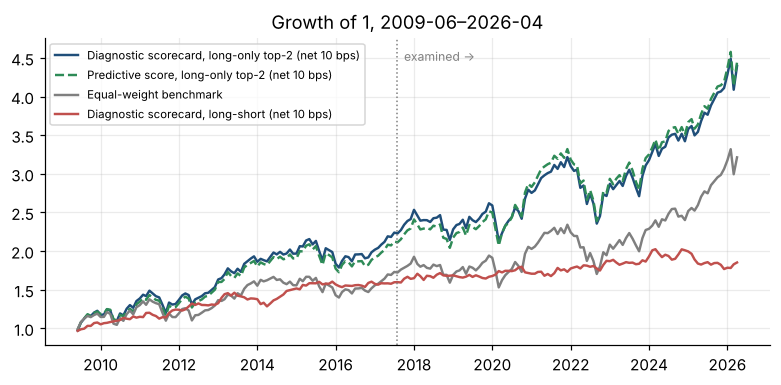

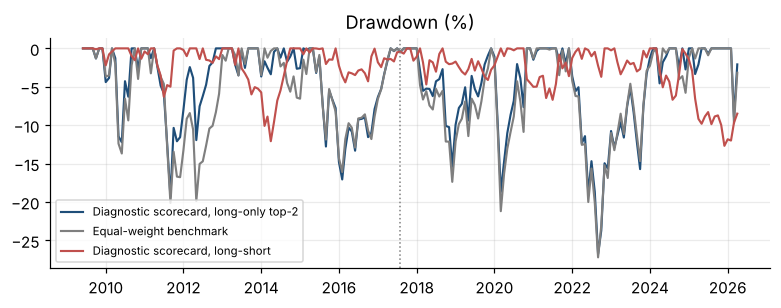

In [10]:
cum = lambda s: (1 + s.loc[START:].fillna(0)).cumprod()
gD, tD, _ = BT[('Diagnostic (4-pillar)', 'LO2')]; gL, tL, _ = BT[('Diagnostic (4-pillar)', 'LS2')]; gP, tP, _ = BT[('Predictive (Macro+Micro)', 'LO2')]
SER = {'Diagnostic scorecard, long-only top-2 (net 10 bps)': (gD - tD * 1e-3, '#1f4e79', '-'),
       'Predictive score, long-only top-2 (net 10 bps)': (gP - tP * 1e-3, '#2e8b57', '--'),
       'Equal-weight benchmark': (EW, '#7f7f7f', '-'),
       'Diagnostic scorecard, long-short (net 10 bps)': (gL - tL * 1e-3, '#c0504d', '-')}
fig, ax = plt.subplots(figsize=(7.2, 3.6))
for lab, (s_, c, ls) in SER.items():
    cc = cum(s_); ax.plot(cc.index.to_timestamp(), cc.values, ls, color=c, label=lab, lw=1.6)
ax.axvline(pd.Timestamp('2017-07-31'), c='grey', ls=':', lw=1)
ax.text(pd.Timestamp('2017-09-30'), ax.get_ylim()[1] * .97, 'examined →', fontsize=8, va='top', color='grey')
ax.set_title(f'Growth of 1, {START}–{AS_OF}'); ax.legend(fontsize=7.5, loc='upper left')
plt.tight_layout(); plt.savefig(CH/'cumulative_vs_benchmark.png', dpi=220, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(7.2, 2.9))
for lab, (s_, c, ls) in list(SER.items())[:1] + list(SER.items())[2:]:
    cc = cum(s_); ax.plot(cc.index.to_timestamp(), (cc / cc.cummax() - 1).values * 100, ls, color=c, label=lab.split(' (')[0], lw=1.4)
ax.axvline(pd.Timestamp('2017-07-31'), c='grey', ls=':', lw=1); ax.set_title('Drawdown (%)'); ax.legend(fontsize=7.5, loc='lower left')
plt.tight_layout(); plt.savefig(CH/'drawdown.png', dpi=220, bbox_inches='tight'); plt.show()

## 6. Step 5 — Investment view, as of the latest common data date
**Disclosure.** The supplied workbooks end 30-Apr-2026 for the US, which binds the five-market panel. This ranking is **as of 30-Apr-2026**, not current. Rahul's instruction is to use only the supplied data, so no external series is used to extend it. Re-running on refreshed exports with the same tickers updates every figure.

In [11]:
t = AS_OF
CUR = pd.DataFrame({'FCI 6M easing (own-sd units)': RAWSIG['Macro'].loc[t], 'EPS revision 6M %': RAWSIG['Micro'].loc[t] * 100,
                    'Forward P/E': PE.loc[t], 'Earnings yield %': EY.loc[t], '2Y yield %': Y2.loc[t], 'Valuation spread %': (EY - Y2).loc[t],
                    'Spread vs own history (z)': RAWSIG['Valuation'].loc[t], 'Trend quality (signed R²)': RAWSIG['Technical'].loc[t],
                    **{f'{p} score': Z[p].loc[t] for p in PILLARS}, **{f'{p} contribution': Z[p].loc[t] / 4 for p in PILLARS},
                    'Diagnostic score': DIAG.loc[t], 'Diagnostic rank': RANK_D.loc[t].astype(int),
                    'Predictive score': PRED.loc[t], 'Predictive rank': RANK_P.loc[t].astype(int)}).sort_values('Diagnostic rank')
callmap = lambda r: 'OVERWEIGHT' if r <= 2 else ('UNDERWEIGHT' if r >= 4 else 'NEUTRAL')
CUR['Call (4-pillar diagnostic)'] = CUR['Diagnostic rank'].map(callmap)
CUR['Call (predictive)'] = CUR['Predictive rank'].map(callmap)
CUR['Agree?'] = np.where(CUR['Call (4-pillar diagnostic)'] == CUR['Call (predictive)'], 'yes', 'NO')
display(CUR.round(2)); CUR.to_csv(OUT/'current_scorecard.csv')
RANKTAB = pd.DataFrame({'Diagnostic rank (4-pillar)': CUR['Diagnostic rank'], 'Call (4-pillar diagnostic)': CUR['Call (4-pillar diagnostic)'],
                        'Predictive rank (Macro+Micro)': CUR['Predictive rank'], 'Call (predictive)': CUR['Call (predictive)'], 'Agree?': CUR['Agree?']})
print('3M and 6M rankings are identical: the pillar scores are horizon-independent. What differs by horizon is the EVIDENCE behind them (§3):')
print('  Macro is supported at both 3M and 6M; Micro is supported at 3M and weak at 6M. So the 6M view rests mainly on Macro.')
display(RANKTAB); RANKTAB.to_csv(OUT/'current_rankings_3m_6m.csv')
FIG['current'] = {c: {'diag_rank': int(CUR.loc[c, 'Diagnostic rank']), 'pred_rank': int(CUR.loc[c, 'Predictive rank']),
                      'diag': float(CUR.loc[c, 'Diagnostic score']), 'pred': float(CUR.loc[c, 'Predictive score']), 'call': CUR.loc[c, 'Call (predictive)'],
                      'call_diag': CUR.loc[c, 'Call (4-pillar diagnostic)'],
                      **{p: float(CUR.loc[c, f'{p} score']) for p in PILLARS}, **{f'{p}_contrib': float(CUR.loc[c, f'{p} contribution']) for p in PILLARS},
                      'fci': float(CUR.loc[c, 'FCI 6M easing (own-sd units)']), 'eps': float(CUR.loc[c, 'EPS revision 6M %']),
                      'pe': float(CUR.loc[c, 'Forward P/E']), 'spread': float(CUR.loc[c, 'Valuation spread %'])} for c in COUNTRIES}
FIG['order'] = CUR.index.tolist()
last6 = RANK_D.iloc[-6:].astype(int); last6.index = last6.index.astype(str); display(last6)
FIG['gap23'] = float(CUR['Diagnostic score'].iloc[1] - CUR['Diagnostic score'].iloc[2])
agree = int((CUR['Call (4-pillar diagnostic)'] == CUR['Call (predictive)']).sum()); FIG['call_agreement'] = agree
FIG['calls_diag'] = CUR['Call (4-pillar diagnostic)'].to_dict(); FIG['calls_pred'] = CUR['Call (predictive)'].to_dict()
print(f'The two views give the SAME call for {agree} of 5 markets. Gap between rank 2 and rank 3 on the diagnostic score: {FIG["gap23"]:.2f}')
print('Where they disagree, the predictive view is the one with out-of-sample evidence; the 4-pillar view is the brief\'s required scorecard. Both are reported.')

,FCI 6M easing (own-sd units),EPS revision 6M %,Forward P/E,Earnings yield %,2Y yield %,Valuation spread %,Spread vs own history (z),Trend quality (signed R²),Macro score,Micro score,Valuation score,Technical score,Macro contribution,Micro contribution,Valuation contribution,Technical contribution,Diagnostic score,Diagnostic rank,Predictive score,Predictive rank,Call (4-pillar diagnostic),Call (predictive),Agree?
US,0.010,16.470,20.700,4.830,0.850,3.990,-1.040,0.680,1.090,1.270,0.690,-0.790,0.270,0.320,0.170,-0.200,0.560,1,1.180,1,OVERWEIGHT,OVERWEIGHT,yes
Japan,-0.220,10.270,17.610,5.680,1.380,4.290,-1.660,0.890,-0.200,0.150,-0.810,1.000,-0.050,0.040,-0.200,0.250,0.040,2,-0.020,2,OVERWEIGHT,OVERWEIGHT,yes
Switzerland,-0.120,1.430,18.330,5.460,0.180,5.280,-0.740,0.650,0.380,-1.430,1.420,-1.080,0.090,-0.360,0.350,-0.270,-0.180,3,-0.530,4,NEUTRAL,UNDERWEIGHT,NO
UK,-0.460,11.690,12.890,7.760,4.450,3.300,-1.600,0.900,-1.590,0.410,-0.660,1.070,-0.400,0.100,-0.160,0.270,-0.190,4,-0.590,5,UNDERWEIGHT,UNDERWEIGHT,yes
Eurozone,-0.130,7.250,14.850,6.730,2.640,4.090,-1.590,0.750,0.320,-0.390,-0.640,-0.200,0.080,-0.100,-0.160,-0.050,-0.230,5,-0.040,3,UNDERWEIGHT,NEUTRAL,NO


3M and 6M rankings are identical: the pillar scores are horizon-independent. What differs by horizon is the EVIDENCE behind them (§3):
  Macro is supported at both 3M and 6M; Micro is supported at 3M and weak at 6M. So the 6M view rests mainly on Macro.


,Diagnostic rank (4-pillar),Call (4-pillar diagnostic),Predictive rank (Macro+Micro),Call (predictive),Agree?
US,1,OVERWEIGHT,1,OVERWEIGHT,yes
Japan,2,OVERWEIGHT,2,OVERWEIGHT,yes
Switzerland,3,NEUTRAL,4,UNDERWEIGHT,NO
UK,4,UNDERWEIGHT,5,UNDERWEIGHT,yes
Eurozone,5,UNDERWEIGHT,3,NEUTRAL,NO


,US,Eurozone,UK,Switzerland,Japan
2025-11,3,4,2,5,1
2025-12,3,5,2,4,1
2026-01,1,4,3,5,2
2026-02,1,4,2,5,3
2026-03,3,5,2,4,1
2026-04,1,5,4,3,2


The two views give the SAME call for 3 of 5 markets. Gap between rank 2 and rank 3 on the diagnostic score: 0.22
Where they disagree, the predictive view is the one with out-of-sample evidence; the 4-pillar view is the brief's required scorecard. Both are reported.


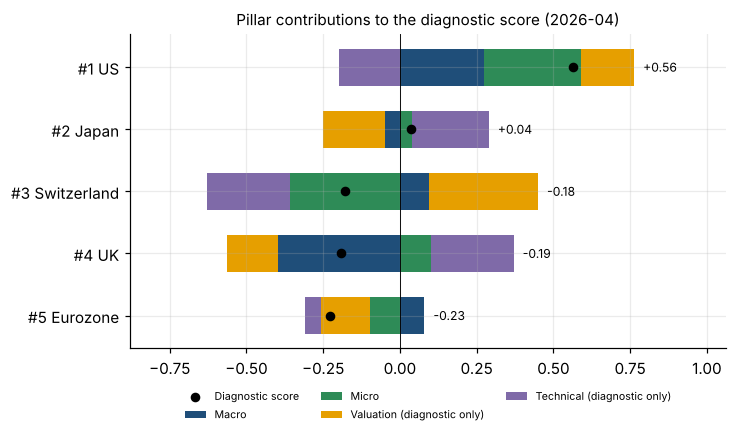

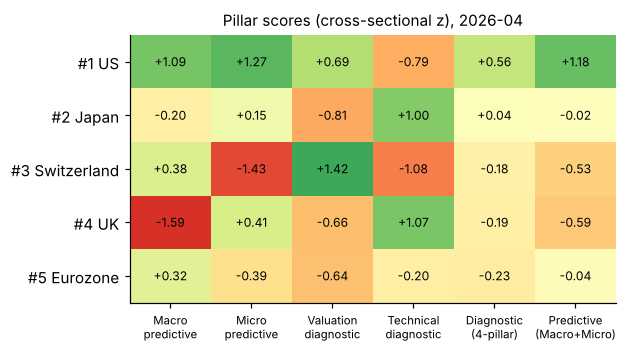

In [12]:
order = CUR.index[::-1]; bp = np.zeros(5); bn = np.zeros(5)
fig, ax = plt.subplots(figsize=(6.8, 4.1))
for p in PILLARS:
    v = CUR.loc[order, f'{p} contribution'].values
    lab = f'{p}' + ('' if FIG['labels'][p].startswith('PREDICTIVE') else ' (diagnostic only)')
    ax.barh(np.arange(5), np.where(v > 0, v, 0), left=bp, color=PCOL[p], label=lab, height=.6)
    ax.barh(np.arange(5), np.where(v < 0, v, 0), left=bn, color=PCOL[p], height=.6)
    bp += np.where(v > 0, v, 0); bn += np.where(v < 0, v, 0)
ax.scatter(CUR.loc[order, 'Diagnostic score'], np.arange(5), color='k', zorder=5, s=28, label='Diagnostic score')
for i, c in enumerate(order): ax.text(max(bp[i], 0) + .03, i, f'{CUR.loc[c, "Diagnostic score"]:+.2f}', va='center', fontsize=8)
ax.set_yticks(np.arange(5)); ax.set_yticklabels([f'#{int(CUR.loc[c, "Diagnostic rank"])} {c}' for c in order]); ax.axvline(0, c='k', lw=.6)
ax.set_title(f'Pillar contributions to the diagnostic score ({AS_OF})', fontsize=10)
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(.5, -.1), ncol=3, frameon=False); ax.set_xlim(bn.min() - .25, bp.max() + .3)
plt.tight_layout(); plt.savefig(CH/'pillar_contributions.png', dpi=220, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(5.8, 3.3))
hm = CUR[[f'{p} score' for p in PILLARS] + ['Diagnostic score', 'Predictive score']]
ax.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
lbl = [f'{p}\n{"predictive" if FIG["labels"][p].startswith("PREDICTIVE") else "diagnostic"}' for p in PILLARS] + ['Diagnostic\n(4-pillar)', 'Predictive\n(Macro+Micro)']
ax.set_xticks(range(6)); ax.set_xticklabels(lbl, fontsize=7.5); ax.set_yticks(range(5)); ax.set_yticklabels([f'#{int(CUR.loc[c, "Diagnostic rank"])} {c}' for c in CUR.index])
for i in range(5):
    for j in range(6): ax.text(j, i, f'{hm.values[i, j]:+.2f}', ha='center', va='center', fontsize=8)
ax.set_title(f'Pillar scores (cross-sectional z), {AS_OF}', fontsize=10); ax.grid(False)
plt.tight_layout(); plt.savefig(CH/'pillar_heatmap.png', dpi=220, bbox_inches='tight'); plt.show()

## 7. Exports, deck figures and the methodology document

In [13]:
panel = pd.concat({'BEst_PE': PE, 'EPS_fwd': EPS, 'FCI_oriented_easier_plus': FCI, 'Yield_2Y_pct': Y2, 'USD_per_local': FX,
                   'reconstructed_index_local': PX, 'reconstructed_index_usd': PX_USD}, axis=1)
panel.index = panel.index.astype(str); panel.to_csv(OUT/'input_monthly_panel.csv')
SIGL = pd.concat({p: RAWSIG[p] for p in PILLARS}, axis=1); SIGL.index = SIGL.index.astype(str); SIGL.to_csv(OUT/'signals_raw_monthly.csv')
PSC = pd.concat({**{p: Z[p] for p in PILLARS}, 'Diagnostic': DIAG, 'Diagnostic_rank': RANK_D, 'Predictive': PRED, 'Predictive_rank': RANK_P}, axis=1)
PSC.index = PSC.index.astype(str); PSC.to_csv(OUT/'pillar_scores_monthly.csv')
HEAD = pd.DataFrame([
 {'figure': 'call agreement (of 5 markets)', 'value': FIG['call_agreement']},
 {'figure': 'gap between diagnostic rank 2 and rank 3', 'value': FIG['gap23']},
 {'figure': 'S&P 500 reconstruction mean abs difference (pp)', 'value': FIG['spx_mad_pp']},
 {'figure': 'panel months', 'value': FIG['panel_months']},
 {'figure': 'scorecard months', 'value': int(valid.sum())},
]).set_index('figure')
display(HEAD.round(3)); HEAD.to_csv(OUT/'headline_figures.csv')
json.dump(FIG, open(OUT/'ppt_figures.json', 'w'), indent=2, default=float)
print('CSV outputs in', OUT.relative_to(ROOT)); print(sorted(p.name for p in OUT.glob('*.csv')))

,value
figure,
call agreement (of 5 markets),3.000
gap between diagnostic rank 2 and rank 3,0.217
S&P 500 reconstruction mean abs difference (pp),0.039
panel months,245.000
scorecard months,204.000


CSV outputs in output/v16
['backtest_monthly.csv', 'backtest_pillar_attribution.csv', 'backtest_summary.csv', 'country_contributions.csv', 'current_rankings_3m_6m.csv', 'current_scorecard.csv', 'frozen_definitions.csv', 'headline_figures.csv', 'input_monthly_panel.csv', 'micro_battery.csv', 'micro_incremental.csv', 'pillar_scores_monthly.csv', 'predictive_power.csv', 'price_decomposition.csv', 'robustness.csv', 'scorecard_history.csv', 'scorecard_ic.csv', 'signal_classification.csv', 'signal_definitions.csv', 'signals_raw_monthly.csv', 'slide_number_registry.csv', 'technical_battery.csv', 'technical_direction_choice.csv', 'technical_orthogonalisation.csv', 'technical_reconciliation.csv', 'technical_verdict.csv', 'technical_wf_monthly.csv', 'technical_wf_picks.csv', 'technical_wf_reconciliation.csv', 'valuation_loo.csv', 'valuation_outliers.csv', 'valuation_subperiods.csv', 'valuation_variants.csv', 'valuation_verdict.csv']


In [14]:
f2 = lambda x: f'{x:+.3f}'
g = lambda w, s, bk, c, col: float(BTS.loc[(w, s, bk, c), col])
D4, PR, EWB = 'Diagnostic (4-pillar)', 'Predictive (Macro+Micro)', 'Equal-weight benchmark'
doc = f"""# Developed-Markets Equity Scorecard — Methodology and Limitations (v16 FINAL)

Generated by `notebook/Markets_Scorecard_v16_FINAL.ipynb`. Supporting research: `notebook/Markets_Scorecard_v16_investigation.ipynb`. Every figure below comes from `output/v16/`.

## 1. Objective
Rank the US, Eurozone, UK, Switzerland and Japan by expected **relative** USD equity performance over the next 3–6 months, using only the supplied assignment dataset.

## 2. Data
- Supplied Bloomberg workbooks only. Monthly panel **{IDX[0]} → {AS_OF}** ({len(IDX)} months), last observation in each month.
- **As-of date {AS_OF}** — the last month in which all five markets report. The US workbook binds.
- **No index price exists in the dataset.** The supplied "Price" workbook contains P/E ratios (values 8–39), not index levels. The index is reconstructed as `P = forward P/E × forward EPS`, an identity. The US reconstruction matches published S&P 500 monthly returns to **{FIG['spx_mad_pp']:.3f} pp**; the other four cannot be validated against a published index with this data.
- Returns are **price returns**. No dividend data is supplied.
- Data-quality findings carried from the audit: Switzerland uses the euro-area FCI and credit series; VIX is one global observation repeated in three workbooks; the UK workbook's "VIX Index" column is not an equity volatility index (correlation 0.05 with VIX, no 2008 or 2020 spike) and is excluded.

## 3. Signals (one per pillar, frozen before evaluation)
| Pillar | Indicator | Construction | Direction |
|---|---|---|---|
""" + "\n".join(f"| {p} | {SIGDOC.loc[p,'indicator']} | {SIGDOC.loc[p,'construction']} | {SIGDOC.loc[p,'direction']} |" for p in PILLARS) + f"""

Rationales are in `signal_definitions.csv`. Each indicator is z-scored across the five markets each month.

**Technical pillar limitation, stated plainly.** Because `log(P_t/P_t−k) = log(PE_t/PE_t−k) + log(EPS_t/EPS_t−k)`, any technical signal built here is a function of the same inputs as the Valuation and Micro pillars. It is **not** an independent fourth source of information. An earlier claim (v14) that a low regression R² demonstrated independence has been **withdrawn**.

## 4. Predictive power
- **Metric:** monthly Spearman rank IC against the next 3M/6M USD return relative to the five-market mean.
- **Windows:** discovery to 2016-12, six-month embargo, **examined** from 2017-07. The examined window was inspected repeatedly across v1–v16 and is **not** untouched holdout data.
- **Inference:** 95% moving-block bootstrap CI, HAC t, block-permutation p.

| Pillar | IC 3M disc → exam | IC 6M disc → exam | ex-US IC 6M | Label |
|---|---|---|---|---|
""" + "\n".join(f"| {p} | {f2(PP.loc[(p,'3M','discovery'),'IC'])} → {f2(PP.loc[(p,'3M','examined'),'IC'])} | {f2(PP.loc[(p,'6M','discovery'),'IC'])} → {f2(PP.loc[(p,'6M','examined'),'IC'])} | {f2(ROB.loc[(p,'6M'),'ex-US IC'])} | {LABELS[p][0]} |" for p in PILLARS) + f"""

**Why Valuation and Technical are diagnostic only**
- *Valuation:* strong in discovery ({f2(PP.loc[('Valuation','6M','discovery'),'IC'])} at 6M) but negative in the examined window ({f2(PP.loc[('Valuation','6M','examined'),'IC'])}). Traced to the **US**, which was persistently the most expensive market on this measure and persistently outperformed from 2017. Excluding the US, the examined 6M IC is positive. Not outlier-driven; a negative-policy-rate explanation was tested and refuted.
- *Technical:* raw 6M IC {f2(PP.loc[('Technical','6M','full'),'IC'])} but only {ROB.loc[('Technical','6M'),'share of IC retained']:.0%} survives removing the other pillars, and it falls to {f2(ROB.loc[('Technical','6M'),'ex-US IC'])} without the US. Six price-path measures were tested with directions frozen on discovery; no momentum variant survives ex-US and reversal is absent.

**Multiple-testing caveat.** These indicators were selected across v1–v16. Selection-adjusted p-values for the strongest are 0.16–0.20; a nominal 5% HAC test over-rejects at 6–9% in samples this short. **No pillar is statistically significant.**

## 5. Scorecard
- **Diagnostic scorecard (primary, as the brief requires):** equal-weight average of the four pillar z-scores; contribution of a pillar = ¼ × its z.
- **Predictive score (companion):** equal-weight average of the PREDICTIVE pillars (Macro, Micro). The two diagnostic pillars are reported with their scores and contributions but carry **zero** predictive weight. They are not deleted and not given artificial importance.
- **Weights are equal and fixed.** Fitting weights to historical IC would be in-sample optimisation.
- 3M and 6M rankings are identical because the scores are horizon-independent; what differs is the supporting evidence (Macro holds at both horizons, Micro at 3M).

| Score | IC 3M disc → exam | IC 6M disc → exam |
|---|---|---|
| Diagnostic (4 pillars) | {f2(SCIC.loc[('Diagnostic (4 pillars, equal weight)','3M','discovery'),'IC'])} → {f2(SCIC.loc[('Diagnostic (4 pillars, equal weight)','3M','examined'),'IC'])} | {f2(SCIC.loc[('Diagnostic (4 pillars, equal weight)','6M','discovery'),'IC'])} → {f2(SCIC.loc[('Diagnostic (4 pillars, equal weight)','6M','examined'),'IC'])} |
| Predictive (Macro + Micro) | {f2(SCIC.loc[('Predictive (Macro + Micro)','3M','discovery'),'IC'])} → {f2(SCIC.loc[('Predictive (Macro + Micro)','3M','examined'),'IC'])} | {f2(SCIC.loc[('Predictive (Macro + Micro)','6M','discovery'),'IC'])} → {f2(SCIC.loc[('Predictive (Macro + Micro)','6M','examined'),'IC'])} |

## 6. Backtest
**Rules, fixed in advance and not optimised:** signal at month-end t earns the t+1 USD price return; long-only = 50% in each top-2 market against a 20% equal-weight benchmark; long-short = ±50% top-2/bottom-2 and ±100% top-1/bottom-1; 6-month overlapping tranches with drift-accurate turnover; one-way costs 0/5/10/20 bps.

**Full period {FIG['bt_window']['full']}, net of 10 bps**

| | Diagnostic long-only | Predictive long-only | EW benchmark | Diagnostic L/S top2 | Diagnostic L/S top1 |
|---|---|---|---|---|---|
| Return % p.a. | {g('full',D4,'long-only top-2',10,'Return % p.a.'):.1f} | {g('full',PR,'long-only top-2',10,'Return % p.a.'):.1f} | {g('full',EWB,'long-only',0,'Return % p.a.'):.1f} | {g('full',D4,'long-short top2/bottom2',10,'Return % p.a.'):.1f} | {g('full',D4,'long-short top1/bottom1',10,'Return % p.a.'):.1f} |
| Volatility % p.a. | {g('full',D4,'long-only top-2',10,'Vol % p.a.'):.1f} | {g('full',PR,'long-only top-2',10,'Vol % p.a.'):.1f} | {g('full',EWB,'long-only',0,'Vol % p.a.'):.1f} | {g('full',D4,'long-short top2/bottom2',10,'Vol % p.a.'):.1f} | {g('full',D4,'long-short top1/bottom1',10,'Vol % p.a.'):.1f} |
| Sharpe | {g('full',D4,'long-only top-2',10,'Sharpe'):.2f} | {g('full',PR,'long-only top-2',10,'Sharpe'):.2f} | {g('full',EWB,'long-only',0,'Sharpe'):.2f} | {g('full',D4,'long-short top2/bottom2',10,'Sharpe'):.2f} | {g('full',D4,'long-short top1/bottom1',10,'Sharpe'):.2f} |
| Max drawdown % | {g('full',D4,'long-only top-2',10,'Max drawdown %'):.1f} | {g('full',PR,'long-only top-2',10,'Max drawdown %'):.1f} | {g('full',EWB,'long-only',0,'Max drawdown %'):.1f} | {g('full',D4,'long-short top2/bottom2',10,'Max drawdown %'):.1f} | {g('full',D4,'long-short top1/bottom1',10,'Max drawdown %'):.1f} |
| **Examined-window Sharpe** | {g('examined',D4,'long-only top-2',10,'Sharpe'):.2f} | {g('examined',PR,'long-only top-2',10,'Sharpe'):.2f} | {g('examined',EWB,'long-only',0,'Sharpe'):.2f} | {g('examined',D4,'long-short top2/bottom2',10,'Sharpe'):.2f} | {g('examined',D4,'long-short top1/bottom1',10,'Sharpe'):.2f} |

Turnover: diagnostic long-only {FIG['bt_extra']['full']['LO_turn']:.1f}× p.a., long-short {FIG['bt_extra']['full']['LS2_turn']:.1f}× p.a. Long-short Sharpe at 0/5/10/20 bps: {FIG['bt_cost']['0']:.2f} / {FIG['bt_cost']['5']:.2f} / {FIG['bt_cost']['10']:.2f} / {FIG['bt_cost']['20']:.2f} — costs are not the binding constraint.

**Single-pillar attribution** (same rules, long-short, examined window): Macro {FIG['attrib']['Macro']['examined']:+.2f}, Micro {FIG['attrib']['Micro']['examined']:+.2f}, Valuation {FIG['attrib']['Valuation']['examined']:+.2f}, Technical {FIG['attrib']['Technical']['examined']:+.2f}.

## 7. Investment view — as of {AS_OF}
| Rank | Market | Diagnostic score | Diagnostic call | Predictive rank | Predictive call |
|---|---|---|---|---|---|
""" + "\n".join(f"| {int(CUR.loc[c,'Diagnostic rank'])} | {c} | {CUR.loc[c,'Diagnostic score']:+.2f} | {CUR.loc[c,'Call (4-pillar diagnostic)']} | {int(CUR.loc[c,'Predictive rank'])} | {CUR.loc[c,'Call (predictive)']} |" for c in CUR.index) + f"""

The two views agree on **{FIG['call_agreement']} of 5** markets. Where they disagree, the predictive view carries the out-of-sample evidence; the four-pillar view is the brief's required scorecard. **Conviction is low:** the gap between rank 2 and rank 3 on the diagnostic score is only {FIG['gap23']:.2f}, rankings moved materially in the final months, and no pillar is statistically significant.

## 8. Limitations
1. **Stale data.** The panel ends 30-Apr-2026. Only the supplied dataset may be used, so the ranking cannot be brought forward. Re-exporting the same tickers and re-running refreshes every figure.
2. **Price return only.** No dividends, which understates higher-yielding markets such as the UK.
3. **No index price.** The index is reconstructed, so the Technical pillar cannot be independent of Micro and Valuation.
4. **Point-in-time status unknown.** Whether the consensus P/E and EPS history are point-in-time snapshots cannot be verified from the workbooks.
5. **Switzerland uses euro-area series** for financial conditions and credit.
6. **US EPS uses a different field** (`Monthly_EPS`) from the other four (`BEst EPS`); it is smoother and drifts up faster.
7. **Small sample and long research history.** Five markets, roughly 17 independent 6-month periods in the examined window, and sixteen research versions. Selection risk is material and is why no result is called significant.
8. **The valuation signal fails specifically on the US**, which a five-market scorecard cannot avoid ranking.
"""
(OUT/'METHODOLOGY_AND_LIMITATIONS.md').write_text(doc, encoding='utf8')
print(doc[:1200])

# Developed-Markets Equity Scorecard — Methodology and Limitations (v16 FINAL)

Generated by `notebook/Markets_Scorecard_v16_FINAL.ipynb`. Supporting research: `notebook/Markets_Scorecard_v16_investigation.ipynb`. Every figure below comes from `output/v16/`.

## 1. Objective
Rank the US, Eurozone, UK, Switzerland and Japan by expected **relative** USD equity performance over the next 3–6 months, using only the supplied assignment dataset.

## 2. Data
- Supplied Bloomberg workbooks only. Monthly panel **2005-12 → 2026-04** (245 months), last observation in each month.
- **As-of date 2026-04** — the last month in which all five markets report. The US workbook binds.
- **No index price exists in the dataset.** The supplied "Price" workbook contains P/E ratios (values 8–39), not index levels. The index is reconstructed as `P = forward P/E × forward EPS`, an identity. The US reconstruction matches published S&P 500 monthly returns to **0.039 pp**; the other four cannot be validated against 